# 04 · Elección de los parámetros (E4)

Los cuadernos anteriores usan la configuración por defecto de Liu, Ting y Zhou (2012): $t = 100$ árboles,
submuestras de tamaño $\psi = 256$ y límite de altura $h_{lim} = \psi - 1$. En este cuaderno estudiamos si otros
valores acercan más el orden de la longitud de ruta media al de la profundidad de Tukey. El experimento E4 repite
los escenarios de E1 (correlación baja, $n = 500$) y E2 (correlación alta, $n = 1000$), con $50$ réplicas, haciendo
variar
$$
\psi \in \{16, 32, 64, 128, 256, 512, n\}, \qquad t \in \{10, 25, 50, 100, 250, 500, 1000\}, \qquad
h_{lim} \in \{\psi - 1, \lceil \log_2 \psi \rceil\},
$$
para iForest y para el EIF. Los distintos valores de $t$ son los primeros árboles de un mismo bosque de $1000$
árboles. Con $h_{lim} = \lceil \log_2 \psi \rceil$, el recorrido se detiene a la altura media de un árbol equilibrado
y se suma el término de ajuste $c(\cdot)$ del tamaño del nodo alcanzado, como en la definición de la longitud de ruta.

In [1]:
import sys

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
import visualizacion as V

pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
E4 = pd.read_csv("../results/E4.csv")
m = V.medias_parametros(E4)
oraculo = E4[E4["variante"] == "Oráculo HD_P"].groupby("escenario")[list(V.MEDIDAS)].mean()
techos = {c: oraculo[c].to_dict() for c in V.MEDIDAS}
oraculo.rename(columns=V.MEDIDAS)

,$\tau_b$,$\rho_S$,$r_{\log}$,$\xi_n$,Solapamiento 5 %,$\tau_b$ centro,$\tau_b$ periferia
escenario,,,,,,,
E4 (E1),0.940,0.994,0.981,0.901,0.841,0.890,0.778
E4 (E2),0.955,0.997,0.987,0.927,0.888,0.916,0.831


La tabla anterior es el techo de cada escenario: la concordancia con $HD(\cdot, P_n)$ de la profundidad
poblacional, que ningún método puede superar de forma sistemática.

## Número de árboles

Con $\psi = 256$, representamos la $\tau_b$ media frente al número de árboles. Las líneas continuas usan
$h_{lim} = \psi - 1$ y las discontinuas $h_{lim} = \lceil \log_2 \psi \rceil$.

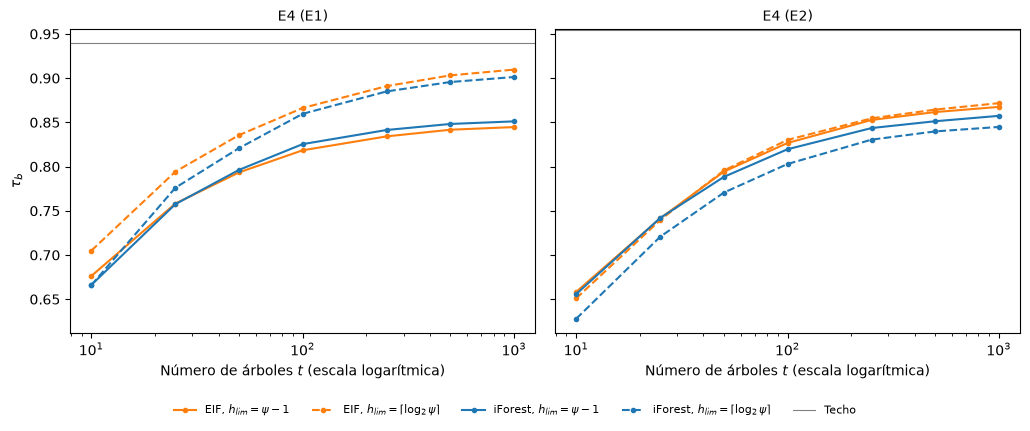

In [2]:
fig = V.dibujar_frente_a_t(m, techos["tau_b"])
V.guardar(fig, "E4_arboles")
plt.show()

Para ver dónde actúa el límite de altura, repetimos la figura con la $\tau_b$ del centro ($50\,\%$ más profundo).

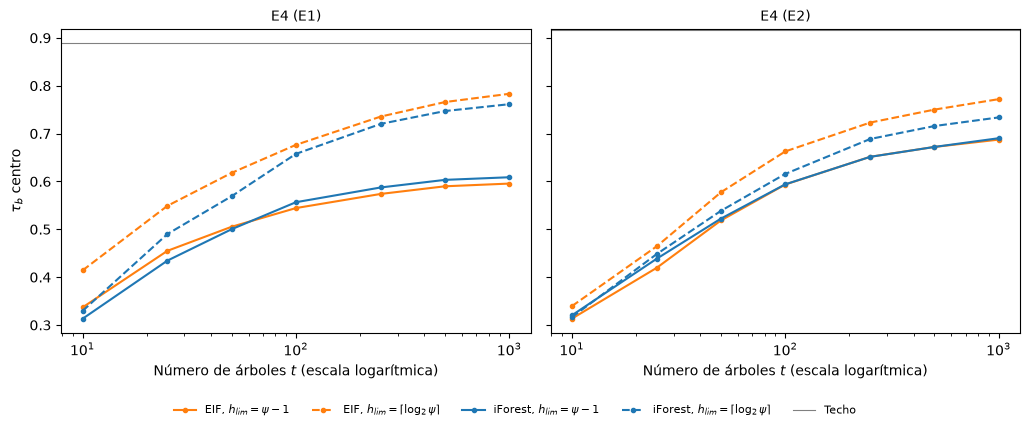

In [3]:
fig = V.dibujar_frente_a_t(m, techos["tau_centro"], medida="tau_centro")
V.guardar(fig, "E4_arboles_centro")
plt.show()

## Tamaño de submuestra

Con $t = 1000$ árboles, representamos la $\tau_b$ y el solapamiento del $5\,\%$ frente al tamaño de submuestra.

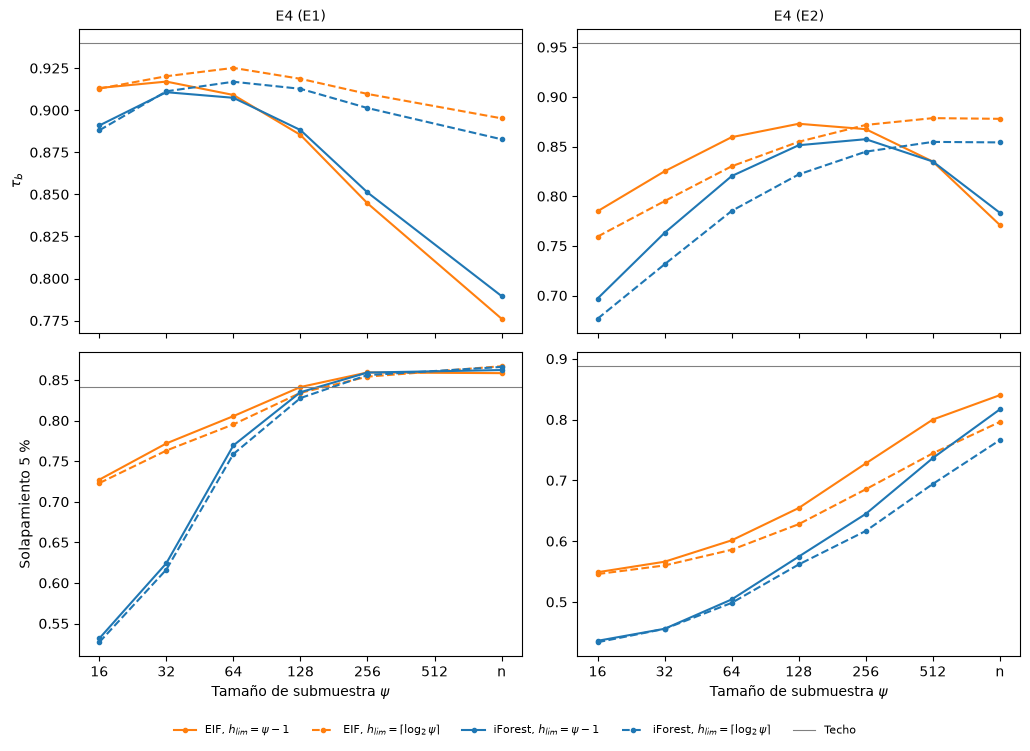

In [4]:
fig = V.dibujar_frente_a_psi(m, techos)
V.guardar(fig, "E4_submuestra")
plt.show()

## Mejores configuraciones

La tabla compara, en cada escenario, la configuración estándar de cada método con la configuración que maximiza la
$\tau_b$ media, y la siguiente con la que maximiza el solapamiento del $5\,\%$.

In [5]:
V.tabla_mejores(m, "tau_b")

$\tau_b$  $\rho_S$  $r_{\log}$  $\xi_n$  Solapamiento 5 %  $\tau_b$ centro  $\tau_b$ periferia
escenario configuración                                                                                                                                 
E4 (E1)   EIF estándar                                       0.818     0.951       0.966    0.730             0.844            0.544               0.759
          iForest estándar                                   0.825     0.955       0.970    0.741             0.847            0.557               0.769
          EIF: psi = 64, t = 1000, h_lim = log2              0.925     0.992       0.981    0.877             0.795            0.847               0.751
          iForest: psi = 64, t = 1000, h_lim = log2          0.917     0.990       0.977    0.866             0.759            0.831               0.717
E4 (E2)   EIF estándar                                       0.827     0.959       0.960    0.743             0.723            0.594               0.644
          iForest estándar                                   0.820     0.956       0.948    0.732             0.640            0.594               0.553
          EIF: psi = 512, t = 1000, h_lim = log2             0.879     0.981       0.966    0.813             0.745            0.760               0.654
          iForest: psi = 256, t = 1000, h_lim = completo     0.857     0.974       0.958    0.785             0.645            0.690               0.565

In [6]:
V.tabla_mejores(m, "sol05")

$\tau_b$  $\rho_S$  $r_{\log}$  $\xi_n$  Solapamiento 5 %  $\tau_b$ centro  $\tau_b$ periferia
escenario configuración                                                                                                                              
E4 (E1)   EIF estándar                                    0.818     0.951       0.966    0.730             0.844            0.544               0.759
          iForest estándar                                0.825     0.955       0.970    0.741             0.847            0.557               0.769
          EIF: psi = n, t = 1000, h_lim = log2            0.895     0.984       0.981    0.835             0.867            0.750               0.794
          iForest: psi = n, t = 500, h_lim = log2         0.877     0.978       0.977    0.810             0.870            0.698               0.793
E4 (E2)   EIF estándar                                    0.827     0.959       0.960    0.743             0.723            0.594               0.644
          iForest estándar                                0.820     0.956       0.948    0.732             0.640            0.594               0.553
          EIF: psi = n, t = 1000, h_lim = completo        0.771     0.926       0.956    0.670             0.840            0.452               0.728
          iForest: psi = n, t = 500, h_lim = completo     0.779     0.931       0.956    0.682             0.819            0.472               0.711

## Observaciones

- **Más árboles acercan el orden al de la profundidad de Tukey, con rendimientos decrecientes.** Con $\psi = 256$ y
  $h_{lim} = \psi - 1$, la $\tau_b$ de iForest pasa de $0.666$ con $t = 10$ a $0.825$ con $t = 100$ y a $0.851$ con
  $t = 1000$ en E1 (de $0.656$ a $0.820$ y $0.857$ en E2), y lo mismo ocurre con el EIF. Con $t = 100$, la media de las
  longitudes de ruta todavía no se ha estabilizado: parte de la diferencia con el techo es ruido de Monte Carlo, que
  desaparece al aumentar $t$. El solapamiento del $5\,\%$ cambia mucho menos (en E2, de $0.640$ a $0.645$ con
  iForest): la cola se determina con pocos árboles.
- **El límite de altura $\lceil \log_2 \psi \rceil$ mejora sobre todo el centro.** Con $t = 1000$, la $\tau_b$ del
  centro pasa de $0.609$ a $0.761$ con iForest y de $0.596$ a $0.783$ con el EIF en E1 (de $0.690$ a $0.734$ y de
  $0.687$ a $0.772$ en E2). Con árboles completos, las observaciones centrales recorren caminos muy largos y parecidos,
  y su diferencia se confunde con la variabilidad de los árboles; al detener el recorrido y sustituir el resto del
  camino por su valor esperado $c(\cdot)$, esa variabilidad se reduce. En cambio, el límite empeora ligeramente la cola.
- **El tamaño de submuestra produce un compromiso entre el centro y la cola.** Submuestras pequeñas favorecen el orden
  global en E1 (el máximo de $\tau_b$ está en $\psi = 64$), pero el solapamiento del $5\,\%$ crece con $\psi$ y es
  máximo con $\psi = n$, en los dos escenarios. En E2, con correlación alta, también la $\tau_b$ global prefiere
  submuestras grandes.
- **Mejores configuraciones.** La que más acerca el orden global a la profundidad de Tukey es el EIF con
  $t = 1000$ y $h_{lim} = \lceil \log_2 \psi \rceil$: con $\psi = 64$ alcanza $\tau_b = 0.925$ en E1 (techo $0.940$)
  y con $\psi = 512$, $0.879$ en E2 (techo $0.955$), frente a $0.818$–$0.827$ con la configuración estándar. Pero esas
  configuraciones empeoran la cola, y la que mejor reproduce el $5\,\%$ menos profundo usa toda la muestra
  ($\psi = n$): en E2, el EIF con árboles completos llega a un solapamiento de $0.840$, frente a $0.723$ con la
  configuración estándar. No hay, por tanto, una configuración que sea la mejor en todo.
- **El techo no es una cota estricta.** En E1, con $\psi \geq 256$, el solapamiento de los dos métodos ($\approx 0.86$)
  supera ligeramente el del techo ($0.841$). Un método calculado sobre la misma muestra que $HD(\cdot, P_n)$ comparte
  parte de su error de muestreo y puede acercarse a ella más que la profundidad poblacional.
- **Las otras medidas de asociación confirman estas conclusiones.** Con $t = 1000$ y
  $h_{lim} = \lceil \log_2 \psi \rceil$, $r_{\log}$ llega a $0.985$–$0.986$ en E1 con $\psi = 256$, por encima incluso
  del techo ($0.981$), y $\xi_n$ a $0.87$–$0.88$ con $\psi = 64$, frente a $0.73$–$0.74$ con la configuración
  estándar y un techo de $0.90$. Con más árboles y el límite de altura, la longitud de ruta media no solo ordena mejor
  las observaciones, sino que queda mucho más determinada por la profundidad.